# NN_L13_mae_models

**Test-year mean absolute error of nine day-ahead forecasts for Romania: naive, LEAR, DNN, N-BEATS, Chronos-2 (with and without covariates), Chronos-Bolt, TimesFM 2.5 and an ensemble; rMAE relative to the naive forecast.**

Neural Networks and Deep Learning (NN), Lecture 13 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L13/NN_L13_mae_models/NN_L13_mae_models.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Every forecast uses only information available at gate closure (12:00 CET on the day before delivery).

MAE naive (EUR/MWh) = 27.74   [acc.naive.mae]
MAE lear (EUR/MWh) = 22.79   [acc.lear.mae]
MAE dnn (EUR/MWh) = 23.06   [acc.dnn.mae]
MAE nbeats (EUR/MWh) = 23.23   [acc.nbeats.mae]
MAE chronos2 (EUR/MWh) = 20.72   [acc.chronos2.mae]
MAE chronos2_cov (EUR/MWh) = 20.41   [acc.chronos2_cov.mae]
MAE bolt (EUR/MWh) = 21.67   [acc.bolt.mae]
MAE timesfm (EUR/MWh) = 22.37   [acc.timesfm.mae]
MAE ens (EUR/MWh) = 20.77   [acc.ens.mae]
rMAE LEAR = 0.822   [acc.lear.rmae]


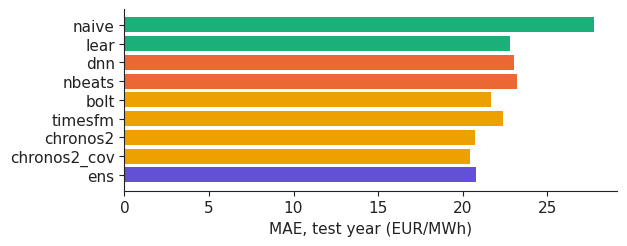

In [3]:
RES = REPO + 'lectures/L13/results/'
F = pd.read_csv(RES + 'forecasts_hourly.csv', parse_dates=['date'])
MODELS = ['naive', 'lear', 'dnn', 'nbeats', 'chronos2', 'chronos2_cov', 'bolt', 'timesfm', 'ens']
mae = {m: float((F[m] - F['actual']).abs().mean()) for m in MODELS}
for m in MODELS:
    show(f'acc.{m}.mae', f'MAE {m} (EUR/MWh)', round(mae[m], 2))
show('acc.lear.rmae', 'rMAE LEAR', round(round(mae['lear'], 2) / round(mae['naive'], 2), 3))
order = ['naive', 'lear', 'dnn', 'nbeats', 'bolt', 'timesfm', 'chronos2', 'chronos2_cov', 'ens']
fig, ax = plt.subplots(figsize=(6.4, 2.6))
ax.barh(range(9), [mae[m] for m in order], color=[PAL['benchmark']] * 2 + [PAL['model']] * 2 + [PAL['alt']] * 4 + ['#6250d6'])
ax.set_yticks(range(9))
ax.set_yticklabels(order)
ax.invert_yaxis()
ax.set_xlabel('MAE, test year (EUR/MWh)')
fig.tight_layout()
fig.savefig('mae_models.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()